<a href="https://colab.research.google.com/github/NismaK/ML_Homeworkbook/blob/main/ML_zoomcamp_homework_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Zoomcamp 2026 — Lead Scoring (ROC AUC, Precision/Recall, CV)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

Check missing values, fill categorical features with `'NA'` and numerical features with `0.0`.

In [2]:
print('Missing values before filling:')
print(df.isna().sum())

categorical_features = df.select_dtypes(include='object').columns.tolist()
numerical_features = [c for c in df.select_dtypes(exclude='object').columns if c != 'converted']
for col in categorical_features:
    df[col] = df[col].fillna('NA')
for col in numerical_features:
    df[col] = df[col].fillna(0.0)

print('\nMissing values after filling:')
print(df.isna().sum())
print('\nCategorical features:', categorical_features)
print('Numerical features:', numerical_features)

Missing values before filling:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Missing values after filling:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


## Split the data

These are the exact split calls requested. The target `converted` is separated from the feature columns.

In [3]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train['converted']
y_val = df_val['converted']
X_train = df_train.drop(columns=['converted'])
X_val = df_val.drop(columns=['converted'])
print('Train:', X_train.shape, '| Validation:', X_val.shape, '| Test:', df_test.shape)
assert 'converted' not in X_train.columns
assert 'converted' not in X_val.columns

Train: (3000, 8) | Validation: (1000, 8) | Test: (1000, 9)


## Question 1 — ROC AUC feature importance

Calculate AUC for each numerical feature using the training set. If AUC is below 0.5, reverse the direction by negating the feature.

In [4]:
feature_aucs = {}
for col in numerical_features:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    feature_aucs[col] = auc

for col, auc in sorted(feature_aucs.items(), key=lambda item: item[1], reverse=True):
    print(f'{col}: {auc:.3f}')
q1_answer = max(feature_aucs, key=feature_aucs.get)
print('\nQ1 answer:', q1_answer)

lead_score: 0.788
interaction_count: 0.765
number_of_courses_viewed: 0.723
annual_income: 0.608

Q1 answer: lead_score


## Question 2 — Train logistic regression and calculate validation AUC

Use `DictVectorizer` for one-hot encoding and the requested model parameters.

In [5]:
dv = DictVectorizer(sparse=True)
X_train_encoded = dv.fit_transform(X_train.to_dict(orient='records'))
X_val_encoded = dv.transform(X_val.to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train_encoded, y_train)
y_val_prob = model.predict_proba(X_val_encoded)[:, 1]
val_auc = roc_auc_score(y_val, y_val_prob)
print(f'Q2 — Validation ROC AUC: {val_auc:.3f}')

Q2 — Validation ROC AUC: 0.732


## Question 3 — Precision and recall curves

Evaluate thresholds from 0.00 to 1.00 in steps of 0.01. Ignore thresholds where both precision and recall are zero when finding the intersection.

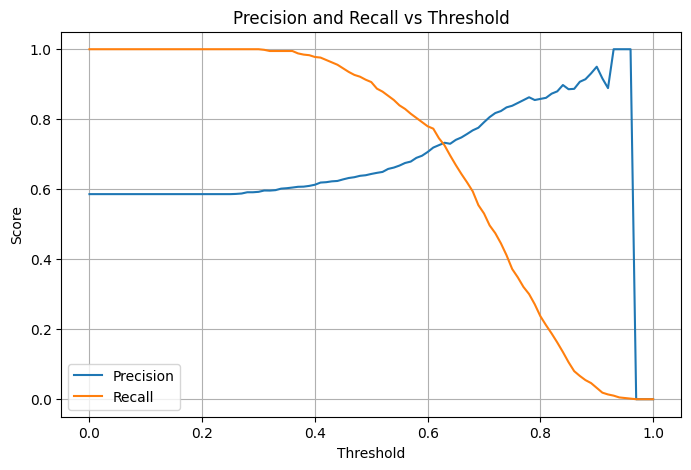

Q3 — Threshold with closest precision/recall: 0.63
Precision=0.733, Recall=0.725


In [6]:
thresholds = np.arange(0.0, 1.001, 0.01)
precisions, recalls = [], []
for threshold in thresholds:
    predictions = (y_val_prob >= threshold).astype(int)
    precisions.append(precision_score(y_val, predictions, zero_division=0))
    recalls.append(recall_score(y_val, predictions, zero_division=0))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()

valid_indices = [i for i, (p, r) in enumerate(zip(precisions, recalls)) if not (p == 0 and r == 0)]
intersection_idx = min(valid_indices, key=lambda i: abs(precisions[i] - recalls[i]))
q3_threshold = thresholds[intersection_idx]
print(f'Q3 — Threshold with closest precision/recall: {q3_threshold:.2f}')
print(f'Precision={precisions[intersection_idx]:.3f}, Recall={recalls[intersection_idx]:.3f}')

## Question 4 — F1 score

Compute F1 at every threshold and identify the threshold with the maximum F1 score.

In [7]:
f1_scores = []
for p, r in zip(precisions, recalls):
    f1_scores.append(2 * p * r / (p + r) if (p + r) > 0 else 0.0)

best_f1_idx = int(np.argmax(f1_scores))
q4_threshold = thresholds[best_f1_idx]
print(f'Q4 — Threshold with maximum F1: {q4_threshold:.2f}')
print(f'Maximum F1: {f1_scores[best_f1_idx]:.3f}')

Q4 — Threshold with maximum F1: 0.41
Maximum F1: 0.758


## Question 5 — 5-Fold cross-validation

Use `KFold(n_splits=5, shuffle=True, random_state=1)` over `df_full_train`. Fit the `DictVectorizer` on each fold's training portion only.

In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)
fold_aucs = []

for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), start=1):
    train_fold = df_full_train.iloc[train_idx]
    val_fold = df_full_train.iloc[val_idx]
    y_fold_train = train_fold['converted']
    y_fold_val = val_fold['converted']
    X_fold_train = train_fold.drop(columns=['converted'])
    X_fold_val = val_fold.drop(columns=['converted'])

    fold_dv = DictVectorizer(sparse=True)
    X_fold_train_enc = fold_dv.fit_transform(X_fold_train.to_dict(orient='records'))
    X_fold_val_enc = fold_dv.transform(X_fold_val.to_dict(orient='records'))
    fold_model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    fold_model.fit(X_fold_train_enc, y_fold_train)
    fold_prob = fold_model.predict_proba(X_fold_val_enc)[:, 1]
    fold_auc = roc_auc_score(y_fold_val, fold_prob)
    fold_aucs.append(fold_auc)
    print(f'Fold {fold}: AUC={fold_auc:.3f}')

q5_std = np.std(fold_aucs)
print(f'Q5 — Standard deviation of fold AUCs: {q5_std:.3f}')

Fold 1: AUC=0.731
Fold 2: AUC=0.730
Fold 3: AUC=0.736
Fold 4: AUC=0.741
Fold 5: AUC=0.721
Q5 — Standard deviation of fold AUCs: 0.007


## Question 6 — Hyperparameter tuning with 5-fold CV

Try `C = [0.000001, 0.001, 1]`. Choose the highest mean AUC; if tied, choose the lowest standard deviation, then the smallest C.

In [9]:
C_values = [0.000001, 0.001, 1]
cv_results = {}

for C in C_values:
    scores = []
    for train_idx, val_idx in kf.split(df_full_train):
        train_fold = df_full_train.iloc[train_idx]
        val_fold = df_full_train.iloc[val_idx]
        y_fold_train = train_fold['converted']
        y_fold_val = val_fold['converted']
        X_fold_train = train_fold.drop(columns=['converted'])
        X_fold_val = val_fold.drop(columns=['converted'])

        fold_dv = DictVectorizer(sparse=True)
        X_fold_train_enc = fold_dv.fit_transform(X_fold_train.to_dict(orient='records'))
        X_fold_val_enc = fold_dv.transform(X_fold_val.to_dict(orient='records'))
        fold_model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        fold_model.fit(X_fold_train_enc, y_fold_train)
        fold_prob = fold_model.predict_proba(X_fold_val_enc)[:, 1]
        scores.append(roc_auc_score(y_fold_val, fold_prob))

    mean_auc = float(np.mean(scores))
    std_auc = float(np.std(scores))
    cv_results[C] = {'mean_auc': mean_auc, 'std_auc': std_auc}
    print(f'C={C}: mean AUC={mean_auc:.3f}, std={std_auc:.3f}')

q6_answer = sorted(C_values, key=lambda C: (-round(cv_results[C]['mean_auc'], 3), round(cv_results[C]['std_auc'], 3), C))[0]
print('\nQ6 — Best C:', q6_answer)

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007

Q6 — Best C: 0.001


## Final answers


In [10]:
print('Q1:', q1_answer)
print(f'Q2: {val_auc:.3f}')
print(f'Q3: {q3_threshold:.2f}')
print(f'Q4: {q4_threshold:.2f}')
print(f'Q5: {q5_std:.3f}')
print('Q6:', q6_answer)

Q1: lead_score
Q2: 0.732
Q3: 0.63
Q4: 0.41
Q5: 0.007
Q6: 0.001
